# 06 — Distribuicoes de Probabilidade

**Objetivos de aprendizagem:** identificar modelos discretos e contínuos, LGN, TCL e erro padrão

**Pré-requisitos:** Notebook 05

**Origem:** Slides, aula 08, páginas 165–179; aprofundamentos: Bernoulli, binomial, Poisson, exponencial, LGN. Conteúdos adicionais estão identificados como **Aprofundamento**.

**Convenção:** `datasets/` reúne dados de entrada; `outputs/` reúne resultados. Dados inventados para demonstrações são sempre identificados como *sintéticos*.

### Materiais complementares

- [Guia Técnico](./reference_materials/06_distribuicoes_de_probabilidade.pdf)
- [Cheat Sheet](./cheat_sheets/cheat_sheet_distribuicoes_de_probabilidade.pdf)


## Preparação do ambiente

Execute a célula abaixo. Os notebooks são independentes e não dependem de variáveis definidas em outros arquivos.

> **Resultados reproduzíveis:** gráficos PNG e tabelas CSV selecionados são gravados automaticamente em `outputs/` ao executar as células na ordem. Os arquivos em `datasets/` são preservados. Esta disciplina usa Matplotlib, não o renderer `iframe` do Plotly.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Execute o JupyterLab com o diretório desta disciplina como raiz.
BASE = Path.cwd()
DATASETS = BASE / "datasets"
OUTPUTS = BASE / "outputs"
DATASETS.mkdir(parents=True, exist_ok=True)
OUTPUTS.mkdir(parents=True, exist_ok=True)

def ler_dataset(nome):
    caminho = DATASETS / nome
    if not caminho.is_file():
        raise FileNotFoundError(f"Dataset não encontrado: {caminho}. Abra o JupyterLab na raiz da disciplina.")
    return pd.read_csv(caminho)

RNG = np.random.default_rng(42)

## 1. Variáveis aleatórias e modelos

Distribuição discreta: função de massa; contínua: densidade cuja integral dá a probabilidade. Densidade pontual não é probabilidade. Parâmetros devem refletir o mecanismo gerador.

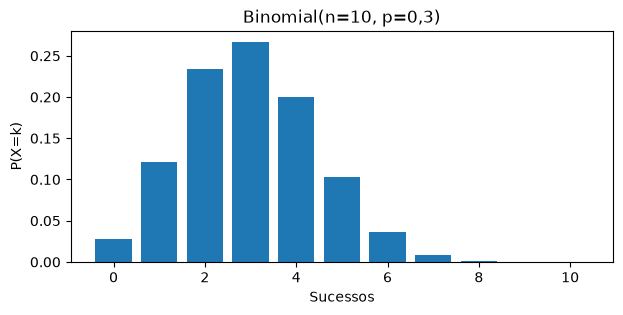

P(X≥4): 0.3503892815999998


In [2]:
from scipy import stats
k=np.arange(0,11)
fig,ax=plt.subplots(figsize=(7,3));ax.bar(k,stats.binom.pmf(k,10,.3));ax.set(title='Binomial(n=10, p=0,3)',xlabel='Sucessos',ylabel='P(X=k)');fig.savefig(OUTPUTS / '06_binomial.png', dpi=160, bbox_inches='tight');plt.show()
print('P(X≥4):',stats.binom.sf(3,10,.3))

## 2. Poisson e exponencial — aprofundamento

Poisson modela contagens de eventos sob condições como taxa constante e independência; exponencial modela tempos entre eventos em um processo de Poisson homogêneo. Nem todo dado de contagem segue Poisson.

P(3 eventos, λ=2): 0.18044704431548356
P(tempo até evento > 2, taxa 0,5): 0.36787944117144233


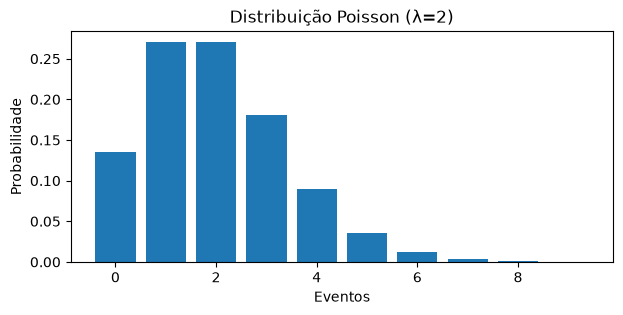

In [3]:
print('P(3 eventos, λ=2):',stats.poisson.pmf(3,2))
print('P(tempo até evento > 2, taxa 0,5):',stats.expon.sf(2,scale=1/.5))
fig,ax=plt.subplots(figsize=(7,3));xs=np.arange(0,10);ax.bar(xs,stats.poisson.pmf(xs,2));ax.set(xlabel='Eventos',ylabel='Probabilidade',title='Distribuição Poisson (λ=2)');fig.savefig(OUTPUTS / '06_poisson.png', dpi=160, bbox_inches='tight');plt.show()

## 3. Normal e padronização

Se X segue normal(μ,σ²), Z=(X−μ)/σ segue a normal padrão. Não assuma normalidade só porque a média e o desvio padrão podem ser calculados.

P(X≤115) 0.8413447460685429


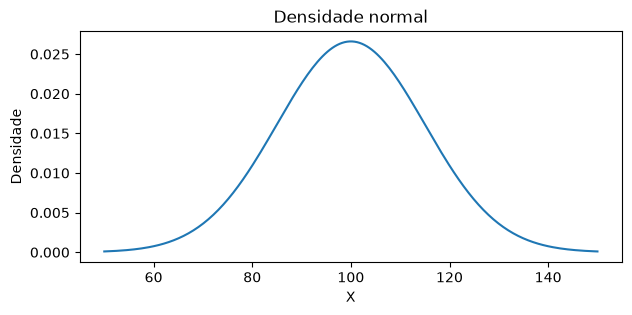

In [4]:
mu,sigma=100,15
print('P(X≤115)',stats.norm.cdf(115,mu,sigma))
t=np.linspace(50,150,200);fig,ax=plt.subplots(figsize=(7,3));ax.plot(t,stats.norm.pdf(t,mu,sigma));ax.set(title='Densidade normal',xlabel='X',ylabel='Densidade');fig.savefig(OUTPUTS / '06_normal.png', dpi=160, bbox_inches='tight');plt.show()

## 4. Lei dos Grandes Números e Teorema Central do Limite — aprofundamento

**LGN:** médias de amostras i.i.d. com esperança finita convergem para a média populacional. **TCL clássico:** com variância finita e hipóteses apropriadas, médias padronizadas tendem à normal quando n cresce.

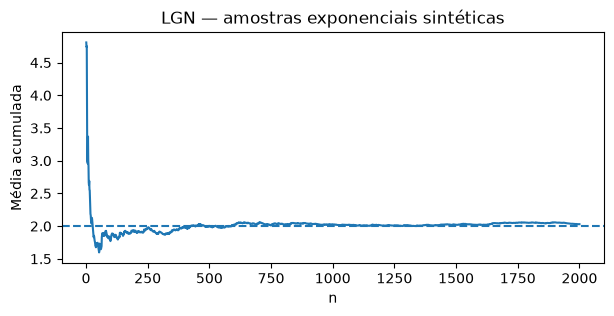

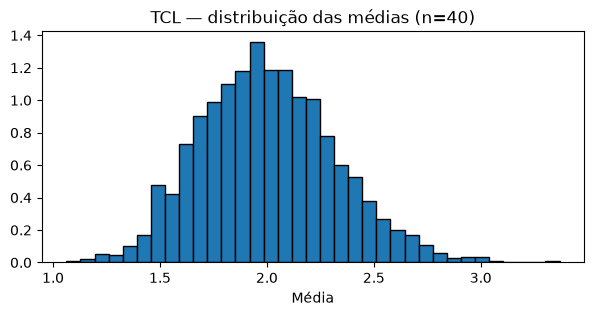

In [5]:
ns=np.arange(1,2001);medias=np.cumsum(RNG.exponential(scale=2,size=2000))/ns
fig,ax=plt.subplots(figsize=(7,3));ax.plot(ns,medias);ax.axhline(2,ls='--');ax.set(title='LGN — amostras exponenciais sintéticas',xlabel='n',ylabel='Média acumulada');fig.savefig(OUTPUTS / '06_lei_grandes_numeros.png', dpi=160, bbox_inches='tight');plt.show()
medias_amostrais=RNG.exponential(scale=2,size=(3000,40)).mean(axis=1)
fig,ax=plt.subplots(figsize=(7,3));ax.hist(medias_amostrais,bins=35,density=True,edgecolor='black');ax.set(title='TCL — distribuição das médias (n=40)',xlabel='Média');fig.savefig(OUTPUTS / '06_teorema_central_limite.png', dpi=160, bbox_inches='tight');plt.show()

In [6]:
# Exportação reproduzível para outputs/ (dados e resultados didáticos)
pd.DataFrame({'n':ns,'media_acumulada':medias}).to_csv(OUTPUTS / '06_lei_grandes_numeros.csv',index=False,encoding='utf-8-sig')
print('Resultados exportados em:', OUTPUTS)

Resultados exportados em: /run/media/eduardo/Backup/Faculdades/PUC - CIENCIA DE DADOS/PUC/02_Disciplinas/03_statistics/outputs


## 5. Erro padrão

Sob observações i.i.d. com variância finita, erro padrão teórico da média é σ/√n. Não é o desvio padrão dos valores individuais.

In [7]:
s=2;n=40;print('Erro padrão teórico para distribuição exponencial com escala 2:',s/np.sqrt(n))
print('Erro padrão empírico da simulação:',medias_amostrais.std(ddof=1))

Erro padrão teórico para distribuição exponencial com escala 2: 0.31622776601683794
Erro padrão empírico da simulação: 0.3183380480066886


### Exercício resolvido — Binomial: probabilidade acumulada

**Solução comentada:**

In [8]:
p=stats.binom.cdf(2,5,.5)
print(p);assert np.isclose(p,0.5)

0.5


In [9]:
# Exportação reproduzível para outputs/ (dados e resultados didáticos)
pd.DataFrame({'modelo':['binomial_n10_p03','poisson_lambda2','normal_mu100_sigma15','binomial_n5_p05'], 'probabilidade':[stats.binom.sf(3,10,.3),stats.poisson.pmf(3,2),stats.norm.cdf(115,100,15),p]}).to_csv(OUTPUTS / '06_probabilidades_modelos.csv',index=False,encoding='utf-8-sig')
print('Resultados exportados em:', OUTPUTS)

Resultados exportados em: /run/media/eduardo/Backup/Faculdades/PUC - CIENCIA DE DADOS/PUC/02_Disciplinas/03_statistics/outputs


**Interpretação:** Para cinco tentativas justas, a probabilidade de até dois sucessos é 0,5 por simetria.

## Erros comuns e limites

Uma distribuição é um modelo: avalie suas hipóteses. O TCL não implica que dados individuais sigam normal nem que qualquer n seja suficiente.

## Consulta Rápida

`stats.binom.pmf(k,n,p)` · `stats.poisson.pmf(k,mu)` · `stats.expon.cdf(t,scale=...)` · `stats.norm.cdf(x,loc,scale)` · `stats.norm.ppf(p)`.

## Autoavaliação

Antes de seguir, explique com suas palavras: **qual é a pergunta estatística, qual método responde a ela, quais pressupostos devem ser verificados e o que não podemos concluir?**

## Aprofundamento v2 — Escolha de distribuição, caudas e pressupostos

A distribuição de Poisson modela contagens não negativas com média igual à variância quando suas condições são adequadas. A binomial modela sucessos em `n` tentativas e a normal é contínua e simétrica. Comparar **média, variância e suporte** ajuda a evitar modelos inadequados.

Em contagens observadas, sobredispersão pode indicar heterogeneidade, dependência ou excesso de zeros. Não concluir que o modelo está correto apenas porque o histograma se parece com a curva.

In [10]:
from scipy import stats
rng_modelo=np.random.default_rng(100)
contagens_poisson=rng_modelo.poisson(lam=3, size=1000)
media_p=contagens_poisson.mean();var_p=contagens_poisson.var(ddof=1)
print('Poisson simulado: média',round(media_p,3),'variância',round(var_p,3),'razão var/média',round(var_p/media_p,3))
assert (contagens_poisson >= 0).all()
assert abs(media_p-3)<0.4

Poisson simulado: média 2.978 variância 2.866 razão var/média 0.963


### Exercício resolvido

**Pergunta:** dados de contagem têm média 3 e variância 25. Devemos iniciar com Poisson sem diagnóstico?

**Solução:** a razão variância/média é cerca de 8,3, sinal de sobredispersão. Investigue estrutura do processo, exposição e alternativas como binomial negativa. A razão por si só não seleciona um modelo definitivamente.